In [159]:
#read the parquet file
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq




Might be to expensive to hedge vega
Consider special cases that we know will happen, we can obviously not hedge directly but we can look at markers that signals that the event will occur and hedge against that.

In [160]:
df = pd.read_parquet("unpivoted_bid_offer_train_clean.parquet", engine="pyarrow")

required = [
        "option_bid", "option_ask",
        "underlying_settlement", "strike",
        "expiration", "date", "option_type"
    ]

df = df.dropna(subset=required)
df['date'] = pd.to_datetime(df['date'])
df.head()

print("data range:", df['date'].min(), "to", df['date'].max())

data range: 2020-01-06 00:00:00 to 2021-04-06 00:00:00


In [161]:

fixing_dates = pd.bdate_range(
    start="2021-02-01",
    end="2021-02-28"
)

print("len(fixing_dates):", len(fixing_dates))

valuation_date = pd.Timestamp("2020-01-06")

theta = (
    (fixing_dates - valuation_date).days / 365
).to_numpy()


len(fixing_dates): 20


In [162]:
print(theta)

[1.0739726  1.07671233 1.07945205 1.08219178 1.08493151 1.09315068
 1.09589041 1.09863014 1.10136986 1.10410959 1.11232877 1.11506849
 1.11780822 1.12054795 1.12328767 1.13150685 1.13424658 1.1369863
 1.13972603 1.14246575]


In [163]:
futures_df = (
    df[[
        "date",
        "future_contract_code",
        "underlying_settlement",
        "underlying_bid",
        "underlying_ask"
    ]]
    .drop_duplicates(subset=["date", "future_contract_code"])
    .copy()
)
options_df = df.dropna(
    subset=[
        "option_bid",
        "option_ask",
        "strike",
        "underlying_settlement",
        "expiration"
    ]
).copy()


options_df["mid_price"] = (
    options_df["option_bid"] + options_df["option_ask"]
) / 2


options_df["settlement_minus_mid"] = (
    options_df["settlement_price"] -
    options_df["mid_price"]
)

print(
    options_df[
        ["settlement_price", "mid_price",
         "settlement_minus_mid"]
    ].describe()
)

       settlement_price      mid_price  settlement_minus_mid
count     121820.000000  121820.000000         121820.000000
mean           8.870714       8.870914             -0.000201
std            7.755050       7.754821              0.002559
min            0.010000       0.035000             -0.055000
25%            2.190000       2.190000              0.000000
50%            6.470000       6.470000              0.000000
75%           14.210000      14.210000              0.000000
max           29.000000      29.000000              0.005000


In [164]:
print(futures_df["future_contract_code"].unique())
futures_df.head()

['COF22' 'COG21' 'COG22' 'COH21' 'COJ21' 'COK21' 'COM21' 'CON21' 'COQ21'
 'COU21' 'COV21' 'COX21' 'COZ21' 'COH22' 'COJ22' 'COK22' 'COM22' 'CON22'
 'COF21' 'COZ20' 'COQ22' 'COU22' 'COV22' 'COX22' 'COZ22' 'COF23' 'COG23']


,date,future_contract_code,underlying_settlement,underlying_bid,underlying_ask
2,2020-01-06,COF22,58.72,58.66,58.78
21,2020-01-06,COG21,62.11,62.10,62.12
42,2020-01-06,COG22,58.52,58.46,58.58
60,2020-01-06,COH21,61.74,61.72,61.76
81,2020-01-06,COJ21,61.40,61.36,61.44


In [165]:
N = fixing_dates.size
print("N:", N)

n1, n2 = N-1,1
w1, w2 = n1/N, n2/N



N: 20


In [166]:
def calculate_d1_d2(f, K, sigma, T,t):
    d1 = (np.log(f / K) + 0.5*sigma ** 2 * (T-t)) / (sigma * np.sqrt(T-t))
    d2 = d1 - sigma * np.sqrt(T-t)
    return d1,d2


In [167]:
def black_76(F, K, sigma, t, T, option_type='call'):
    d1, d2 = calculate_d1_d2(F, K, sigma,T, t)

    if option_type == 'call':
        return (F * norm.cdf(d1) - K * norm.cdf(d2))

    elif option_type == 'put':
        return K * norm.cdf(-d2) - F * norm.cdf(-d1)

    else:
        raise ValueError("Invalid option type")


def implied_volatility(f, K, T, t, market_price, option_type='call', tol=1e-5, max_iterations=100):
    objective_function = lambda sigma: black_76(f, K, sigma, t, T, option_type) - market_price
    return brentq(objective_function, 1e-6, 5, xtol=tol, maxiter=max_iterations)


F = 75
K = 78
sigma = 0.30
t = 0
T = 1

call = black_76(F, K, sigma, t, T, "call")
put = black_76(F, K, sigma, t, T, "put")

assert np.isclose(call - put, F - K)

estimated_sigma = implied_volatility(
    F, K, T, t, call, "call"
)

assert np.isclose(estimated_sigma, sigma)

In [168]:
def estimate_rho(data, recalibration_date):
    endDate = recalibration_date
    workingData = data[(data["date"] <= endDate)]

    tickers = ["COJ21","COK21"]
    prices = (
    futures_df.loc[futures_df["date"] <= endDate]
    .pivot(index="date", columns="future_contract_code",
           values="underlying_settlement")
    .sort_index()
    [tickers]
    .dropna())

    returns = np.log(prices / prices.shift(1)).dropna()
    rho = returns["COJ21"].corr(returns["COK21"])
    return rho

rho = estimate_rho(df, pd.Timestamp("2021-02-16"))

In [169]:


F = 75
K = 78
tau = 1.0
market_price = 7.5

iv = implied_volatility(
    f=F,
    K=K,
    t=0,
    T=tau,
    market_price=market_price,
    option_type="call"
)

reconstructed_price = black_76(
    F, K, iv, 0, tau, "call"
)

print(f"Market price: {market_price:.6f}")
print(f"Model price:  {reconstructed_price:.6f}")
print(f"Difference:   {reconstructed_price - market_price:.8f}")

Market price: 7.500000
Model price:  7.500000
Difference:   0.00000020


In [170]:
D = 0.5


def simulate_correlated_futures(
    F1, F2,
    sigma1, sigma2,
    rho, theta, n1,D,K=78,
    n_simulations=10000
):
    N = len(theta)
    w1,w2 = n1/N, (N-n1)/N
    sigma = np.where(
        np.arange(N) < n1,
        sigma1,
        sigma2
    )

    mu = -0.5 * sigma**2 * theta
    min_theta = np.minimum.outer(theta, theta)

    Sigma = np.zeros((N, N))

    for a in range(N):
        for b in range(N):
            #minimum of theta[a] and theta[b]
            min_theta = min(theta[a], theta[b])
            if a < n1 and b < n1:
            # Both fixings use Apr21
                Sigma[a, b] = sigma1**2 * min_theta
            elif a >= n1 and b >= n1:
            # Both fixings use May21
                Sigma[a, b] = sigma2**2 * min_theta
            else:
            # One fixing uses Apr21, the other May21
                Sigma[a, b] = rho * sigma1 * sigma2 * min_theta

    Chol = np.linalg.cholesky(Sigma)
    Z = np.random.normal(size=(N, n_simulations))
    eta = mu[:, np.newaxis] + Chol @ Z
    F0 = np.where(np.arange(N) < n1, F1, F2)
    forward_prices = F0[:, None] * np.exp(eta)
    #A1 = np.mean(forward_prices[:n1, :], axis=0)
    #A2 = np.mean(forward_prices[n1:, :], axis=0 )
    #A = w1 * A1 + w2 * A2

    A = forward_prices.mean(axis=0)

    mcStd = A.std(ddof=1) / np.sqrt(A.size)
    AMean = A.mean()
    print(f"Monte Carlo mean: {AMean:.6f}, Monte Carlo std: {mcStd:.6f}")
    Payoff_call = np.maximum(A - K, 0)
    Payoff_put = np.maximum(K - A, 0)
    price_call = D*np.mean(Payoff_call)
    price_put = D*np.mean(Payoff_put)
    std_call = D*np.std(Payoff_call)/np.sqrt(n_simulations)
    std_put = D*np.std(Payoff_put)/np.sqrt(n_simulations)
    return price_call, price_put, std_call, std_put


In [171]:
F = 75.0
K_test = 78.0
sigma = 0.30
np.random.seed(42)

for T in (0.25, 0.5, 1.0):
    theta_test = np.array([T])  # En fixing vid T, med t = 0

    call_exact = black_76(F, K_test, sigma, 0.0, T, "call")
    put_exact = black_76(F, K_test, sigma, 0.0, T, "put")

    for M in (10_000, 100_000, 1_000_000):
        call_mc, put_mc, se_call, se_put = simulate_correlated_futures(
            F1=F,
            F2=F,
            sigma1=sigma,
            sigma2=sigma,
            rho=0.0,
            theta=theta_test,
            n1=1,
            D=1.0,
            K=K_test,
            n_simulations=M,
        )

        print(f"\nT = {T:.2f} år, M = {M:,}")

        for label, mc, exact, se in (
            ("Call", call_mc, call_exact, se_call),
            ("Put", put_mc, put_exact, se_put),
        ):
            lower = mc - 1.96 * se
            upper = mc + 1.96 * se
            inside = lower <= exact <= upper

            print(
                f"{label}: MC = {mc:.5f}, Black–76 = {exact:.5f}, "
                f"SE = {se:.5f}, 95 % KI = [{lower:.5f}, {upper:.5f}], "
                f"Black–76 inom KI = {inside}"
            )

Monte Carlo mean: 74.981866, Monte Carlo std: 0.113541

T = 0.25 år, M = 10,000
Call: MC = 3.23061, Black–76 = 3.22872, SE = 0.06219, 95 % KI = [3.10871, 3.35251], Black–76 inom KI = True
Put: MC = 6.24874, Black–76 = 6.22872, SE = 0.07060, 95 % KI = [6.11036, 6.38713], Black–76 inom KI = True
Monte Carlo mean: 75.025907, Monte Carlo std: 0.035779

T = 0.25 år, M = 100,000
Call: MC = 3.24094, Black–76 = 3.22872, SE = 0.01956, 95 % KI = [3.20261, 3.27928], Black–76 inom KI = True
Put: MC = 6.21503, Black–76 = 6.22872, SE = 0.02224, 95 % KI = [6.17144, 6.25863], Black–76 inom KI = True
Monte Carlo mean: 74.981993, Monte Carlo std: 0.011319

T = 0.25 år, M = 1,000,000
Call: MC = 3.22478, Black–76 = 3.22872, SE = 0.00618, 95 % KI = [3.21267, 3.23688], Black–76 inom KI = True
Put: MC = 6.24278, Black–76 = 6.22872, SE = 0.00705, 95 % KI = [6.22897, 6.25660], Black–76 inom KI = False
Monte Carlo mean: 74.837724, Monte Carlo std: 0.160773

T = 0.50 år, M = 10,000
Call: MC = 5.00015, Black–76 =

In [172]:
def price_asian_basket(f1, f2, Favg, K=78):

    K1 = f1 * K / Favg
    K2 = f2 * K / Favg

    sigma1 = float(smile_apr21(K1))
    sigma2 = float(smile_may21(K2))

    return K1, K2, sigma1, sigma2


"""
class forward():
    def __init__(self, K, tau):
        self.K = K
        self.tau = tau
        self.type = "forward"
    
    def price(self, F, sigma, t, T):
        return F * np.exp(-0.01 * (T-t)) - self.K * np.exp(-0.01 * (T-t))

class asian_basket():
    def __init__(self, K, tau, n1, n2):
        self.K = K
        self.tau = tau
        self.n1 = n1
        self.n2 = n2
        self.type = "asian_basket"
    
    def price(self, F1, F2, sigma1, sigma2, rho, theta, D):
        return simulate_correlated_futures(
            F1, F2,
            sigma1, sigma2,
            rho, theta,
            self.n1,D
        )[:2]

    K1 = 
"""

'\nclass forward():\n    def __init__(self, K, tau):\n        self.K = K\n        self.tau = tau\n        self.type = "forward"\n\n    def price(self, F, sigma, t, T):\n        return F * np.exp(-0.01 * (T-t)) - self.K * np.exp(-0.01 * (T-t))\n\nclass asian_basket():\n    def __init__(self, K, tau, n1, n2):\n        self.K = K\n        self.tau = tau\n        self.n1 = n1\n        self.n2 = n2\n        self.type = "asian_basket"\n\n    def price(self, F1, F2, sigma1, sigma2, rho, theta, D):\n        return simulate_correlated_futures(\n            F1, F2,\n            sigma1, sigma2,\n            rho, theta,\n            self.n1,D\n        )[:2]\n\n    K1 = \n'

In [173]:
daily_options = options_df[
    options_df["date"] == "2020-01-06"
].copy()

print(
    daily_options[
        ["future_contract_code", "option_contract_code"]
    ].drop_duplicates()
)

    future_contract_code option_contract_code
2                  COF22                 COF2
21                 COG21                 COG1
42                 COG22                 COG2
60                 COH21                 COH1
81                 COJ21                 COJ1
101                COK21                 COK1
120                COM21                 COM1
142                CON21                 CON1
164                COQ21                 COQ1
185                COU21                 COU1
208                COV21                 COV1
228                COX21                 COX1
246                COZ21                 COZ1


In [174]:
valuation_date = pd.Timestamp("2020-01-06")

apr21_options = daily_options[
    daily_options["future_contract_code"] == "COJ21"
].copy()

may21_options = daily_options[
    daily_options["future_contract_code"] == "COK21"
].copy()

print("Apr21 observations:", len(apr21_options))
print("May21 observations:", len(may21_options))

Apr21 observations: 18
May21 observations: 18


In [175]:
print(
    apr21_options["underlying_settlement"].unique()
)

print(
    may21_options["underlying_settlement"].unique()
)

F1 = 61.4
F2 = 61.05
Favg = w1*F1+w2*F2

[61.4]
[61.05]


In [176]:
columns = [
    "strike",
    "option_type",
    "expiration",
    "time_to_expiry_days",
    "option_bid",
    "option_ask",
    "settlement_price"
]

print("APR21 OPTIONS")
print(apr21_options[columns].sort_values("strike").to_string(index=False))

print("\nMAY21 OPTIONS")
print(may21_options[columns].sort_values("strike").to_string(index=False))

APR21 OPTIONS
 strike option_type expiration  time_to_expiry_days  option_bid  option_ask  settlement_price
   45.0        Call 2021-02-23                  414       17.55       17.85             17.70
   45.0         Put 2021-02-23                  414        1.10        1.50              1.30
   50.0        Call 2021-02-23                  414       13.58       13.92             13.75
   50.0         Put 2021-02-23                  414        2.18        2.52              2.35
   55.0        Call 2021-02-23                  414       10.12       10.44             10.28
   55.0         Put 2021-02-23                  414        3.79        3.97              3.88
   60.0        Call 2021-02-23                  414        7.14        7.36              7.25
   60.0         Put 2021-02-23                  414        5.72        5.98              5.85
   65.0        Call 2021-02-23                  414        4.60        4.86              4.73
   65.0         Put 2021-02-23                

In [177]:
def calculate_smile_points(options):
    data = options.copy()

    # Select out-of-the-money options
    is_otm = (
        ((data["option_type"].str.lower() == "put") &
         (data["strike"] < data["underlying_settlement"])) |
        ((data["option_type"].str.lower() == "call") &
         (data["strike"] >= data["underlying_settlement"]))
    )

    data = data.loc[is_otm].copy()

    # Calculate mid-prices
    data["mid_price"] = (
        data["option_bid"] + data["option_ask"]
    ) / 2

    # Time to expiration in years/
    data["tau"] = data["time_to_expiry_days"] / 365

    # Compute implied volatility
    def compute_iv(row):
        try:
            return implied_volatility(
                f=row["underlying_settlement"],
                K=row["strike"],
                T=row["tau"],
                t=0,
                market_price=row["mid_price"],
                option_type=row["option_type"].lower()
            )
        except (ValueError, RuntimeError):
            return np.nan

    data["implied_vol"] = data.apply(compute_iv, axis=1)

    return data.dropna(subset=["implied_vol"])

In [178]:
apr21_smile_data = calculate_smile_points(apr21_options)
may21_smile_data = calculate_smile_points(may21_options)

print(
    apr21_smile_data[
        ["strike", "implied_vol"]
    ].sort_values("strike")
)

print(
    may21_smile_data[
        ["strike", "implied_vol"]
    ].sort_values("strike")
)

    strike  implied_vol
91    45.0     0.287981
92    50.0     0.277759
93    55.0     0.267741
94    60.0     0.253830
85    65.0     0.237876
86    70.0     0.223546
87    75.0     0.214724
88    80.0     0.212941
89    85.0     0.216153
     strike  implied_vol
111    45.0     0.283232
112    50.0     0.273577
113    55.0     0.263079
114    60.0     0.249537
105    65.0     0.234299
106    70.0     0.220758
107    75.0     0.212216
108    80.0     0.209982
109    85.0     0.212277


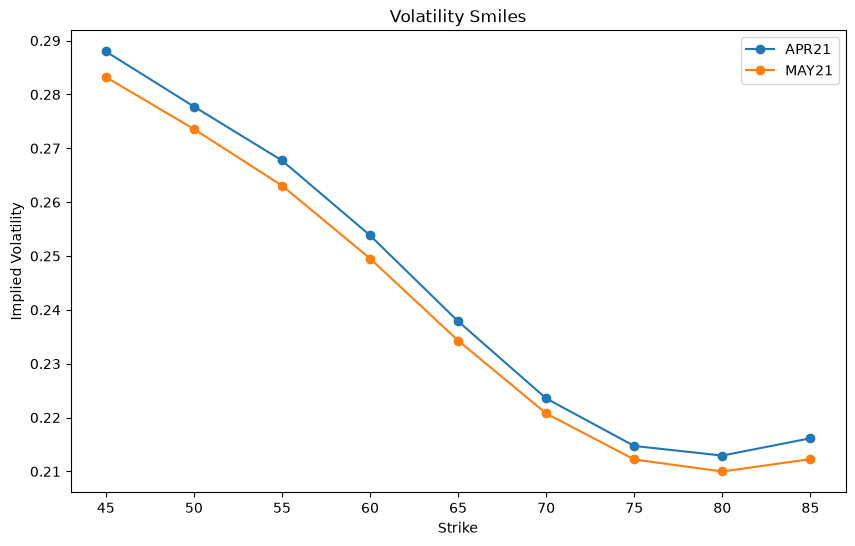

In [179]:
#plot the implied volatility smiles for both contracts

plt.figure(figsize=(10, 6))
apr_sorted = apr21_smile_data.sort_values("strike")
may_sorted = may21_smile_data.sort_values("strike")

plt.plot(apr_sorted["strike"], apr_sorted["implied_vol"], "o-", label="APR21")
plt.plot(may_sorted["strike"], may_sorted["implied_vol"], "o-", label="MAY21")
plt.xlabel("Strike")
plt.ylabel("Implied Volatility")
plt.title("Volatility Smiles")
plt.legend()
plt.show()

In [180]:
from scipy.interpolate import PchipInterpolator

smile_apr21 = PchipInterpolator(
    apr_sorted["strike"],
    apr_sorted["implied_vol"],
    extrapolate=False
)

smile_may21 = PchipInterpolator(
    may_sorted["strike"],
    may_sorted["implied_vol"],
    extrapolate=False
)

In [181]:
K = 78
def get_volatility(F1,F2,Favg,K, smile_apr21, smile_may21):
    K1 = K/Favg*F1
    K2 = K/Favg*F2

    sigma_apr = float(smile_apr21(K1))
    sigma_may = float(smile_may21(K2))
    return sigma_apr, sigma_may


sigmaApr, sigmaMay = get_volatility(F1,F2,Favg,K, smile_apr21, smile_may21)



In [182]:
# Smoke test for the simulation
F1_test, F2_test = 61.40, 61.05
n1_test = 19
K_test = 78.0  # Match the strike currently hard-coded in the function
N_test = len(theta)

assert N_test == 20, f"Expected 20 fixings, got {N_test}"

call, put, se_call, se_put = simulate_correlated_futures(
    F1=F1_test,
    F2=F2_test,
    sigma1=sigmaApr,
    sigma2=sigmaMay,
    rho=rho,
    theta=theta,
    n1=n1_test,
    D=1.0,
    n_simulations=100_000,
)

expected_A = (n1_test * F1_test + (N_test - n1_test) * F2_test) / N_test
simulated_A = call - put + K_test
error = simulated_A - expected_A

# Conservative upper bound for the standard error of call - put
se_bound = se_call + se_put
tolerance = 4 * se_bound

print(f"Expected mean of A:  {expected_A:.4f}")
print(f"Simulated mean of A: {simulated_A:.4f}")
print(f"Difference:          {error:+.4f}")
print(f"Test tolerance:      {tolerance:.4f}")

assert abs(error) <= tolerance, "Simulated mean is too far from the expected mean."
print("PASS")

Monte Carlo mean: 61.404269, Monte Carlo std: 0.043781
Expected mean of A:  61.3825
Simulated mean of A: 61.4043
Difference:          +0.0218
Test tolerance:      0.2007
PASS


In [183]:
valuation_date = pd.Timestamp("2020-01-06")
F1, F2 = 61.40, 61.05
n1, n2 = 19, 1
K_call = 78.0

assert len(fixing_dates) == n1 + n2

theta_call = (fixing_dates - valuation_date).days.to_numpy() / 365.0
Favg = (n1 * F1 + n2 * F2) / (n1 + n2)

sigma_apr, sigma_may = get_volatility(
    F1, F2, Favg, K_call, smile_apr21, smile_may21
)

assert np.isfinite([sigma_apr, sigma_may]).all(), (
    "En mappad strike ligger utanför smilets intervall."
)

rho_initial = 0.99  # Illustrativt antagande vid startdatumet
D = 1.0             # Odiskonterad provkörning

np.random.seed(42)

call_price, _, call_se, _ = simulate_correlated_futures(
    F1=F1,
    F2=F2,
    sigma1=sigma_apr,
    sigma2=sigma_may,
    rho=rho_initial,
    theta=theta_call,
    n1=n1,
    D=D,
    K=K_call,
    n_simulations=200_000,
)

print(f"Förväntat basketgenomsnitt: {Favg:.4f} USD/bbl")
print(f"Volatilitet Apr21: {sigma_apr:.2%}")
print(f"Volatilitet May21: {sigma_may:.2%}")
print(f"Callpris: {call_price:.4f} USD/bbl")
print(f"Monte Carlo-standardfel: {call_se:.4f} USD/bbl")

Monte Carlo mean: 61.389873, Monte Carlo std: 0.030976
Förväntat basketgenomsnitt: 61.3825 USD/bbl
Volatilitet Apr21: 21.33%
Volatilitet May21: 21.06%
Callpris: 1.1091 USD/bbl
Monte Carlo-standardfel: 0.0095 USD/bbl


In [186]:
from scipy.stats import norm

def asianBasket(K):
    # Putens payoff är noll vid K = 0.
    if K == 0:
        return -call_price

    K_apr = K * F1 / Favg
    K_may = K * F2 / Favg

    # Samma flata extrapolering som i din Monte Carlo-version.
    sigma_apr = float(smile_apr21(max(K_apr, smile_apr21.x[0])))
    sigma_may = float(smile_may21(max(K_may, smile_may21.x[0])))

    if not np.isfinite([sigma_apr, sigma_may]).all():
        raise ValueError(f"Mappad strike ligger utanför smilet för K={K:.4f}")

    N = len(theta_call)
    is_apr = np.arange(N) < n1
    futures_at_start = np.where(is_apr, F1, F2)
    sigma = np.where(is_apr, sigma_apr, sigma_may)

    same_leg = is_apr[:, None] == is_apr[None, :]
    correlation = np.where(same_leg, 1.0, rho_initial)

    # Kovarians mellan log-fixingar enligt ekvation (8).
    log_cov = (
        correlation
        * np.outer(sigma, sigma)
        * np.minimum.outer(theta_call, theta_call)
    )

    # Kovarians mellan fixingpriser enligt ekvation (13).
    fixing_cov = np.outer(futures_at_start, futures_at_start) * np.expm1(log_cov)
    var_A = fixing_cov.sum() / N**2

    # Moment matching och putpris enligt ekvation (21), (23) och (24).
    v2 = np.log1p(var_A / Favg**2)
    v = np.sqrt(v2)
    d1 = (np.log(Favg / K) + 0.5 * v2) / v
    d2 = d1 - v

    put_price = D * (K * norm.cdf(-d2) - Favg * norm.cdf(-d1))
    return put_price - call_price

In [187]:
K_grid = np.sort(np.r_[np.linspace(lower, upper, 31), K_put])
h_grid = np.array([asianBasket(K) for K in K_grid])

print("Icke-avtagande på rutnätet:", np.all(np.diff(h_grid) >= -1e-8))

Icke-avtagande på rutnätet: True
